In [1]:
!pip install pandas numpy matplotlib scikit-learn

# 168-Hour Extrapolation (Device 08 - Highest Hours)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# 1. Load Data for Device 08 (Highest hours in dataset: ~131.9h)
df = pd.read_csv('/Users/anshul/Documents/AI/data/raw/MOSFET/MOSFET_Device_08.csv')
df = df.dropna(subset=['Aging_Hours', 'RDS_on_Ohm']).sort_values('Aging_Hours')

print(f"Loaded {len(df)} valid data points for Device 08.")
print(f"Max observed hour: {df['Aging_Hours'].max():.2f}h")


Loaded 64176 valid data points for Device 08.
Max observed hour: 131.92h


In [3]:
# 2. Fit Time-Series Curve
X_train = df[['Aging_Hours']]
y_train = df['RDS_on_Ohm']
baseline_rds = df['Baseline_RDS_Ohm'].iloc[0]

model_linear = LinearRegression()
model_linear.fit(X_train, y_train)

model_poly = make_pipeline(PolynomialFeatures(2), LinearRegression())
model_poly.fit(X_train, y_train)

print("Models trained successfully on all available hours (0 - 131.9h).")


Models trained successfully on all available hours (0 - 131.9h).


In [4]:
# 3. Forecast 168 Hours
X_future = pd.DataFrame({'Aging_Hours': [168.0]})

pred_168h_linear = model_linear.predict(X_future)[0]
pred_168h_poly = model_poly.predict(X_future)[0]

deg_pct_linear = ((pred_168h_linear - baseline_rds) / baseline_rds) * 100
deg_pct_poly = ((pred_168h_poly - baseline_rds) / baseline_rds) * 100

print("--- 168-HOUR FORECAST ---")
print(f"Baseline RDS_on: {baseline_rds:.4f} Ohm")
print(f"Predicted RDS_on at 168h (Linear): {pred_168h_linear:.4f} Ohm  ({deg_pct_linear:+.2f}%)")
print(f"Predicted RDS_on at 168h (Poly):   {pred_168h_poly:.4f} Ohm  ({deg_pct_poly:+.2f}%)")


--- 168-HOUR FORECAST ---
Baseline RDS_on: 0.8366 Ohm
Predicted RDS_on at 168h (Linear): 2.4592 Ohm  (+193.94%)
Predicted RDS_on at 168h (Poly):   2.6096 Ohm  (+211.92%)


In [5]:
# 4. Anomaly Flagging
safety_threshold_pct = 5.0
print("--- ANOMALY / BURN-IN SCREENING REPORT ---")
if deg_pct_linear > safety_threshold_pct:
    print(f"STATUS: FLAGGED (REJECT) - Projected degradation of {deg_pct_linear:.2f}% exceeds {safety_threshold_pct}% threshold.")
else:
    print(f"STATUS: PASS - Projected degradation of {deg_pct_linear:.2f}% is within safe limits.")


--- ANOMALY / BURN-IN SCREENING REPORT ---
STATUS: FLAGGED (REJECT) - Projected degradation of 193.94% exceeds 5.0% threshold.


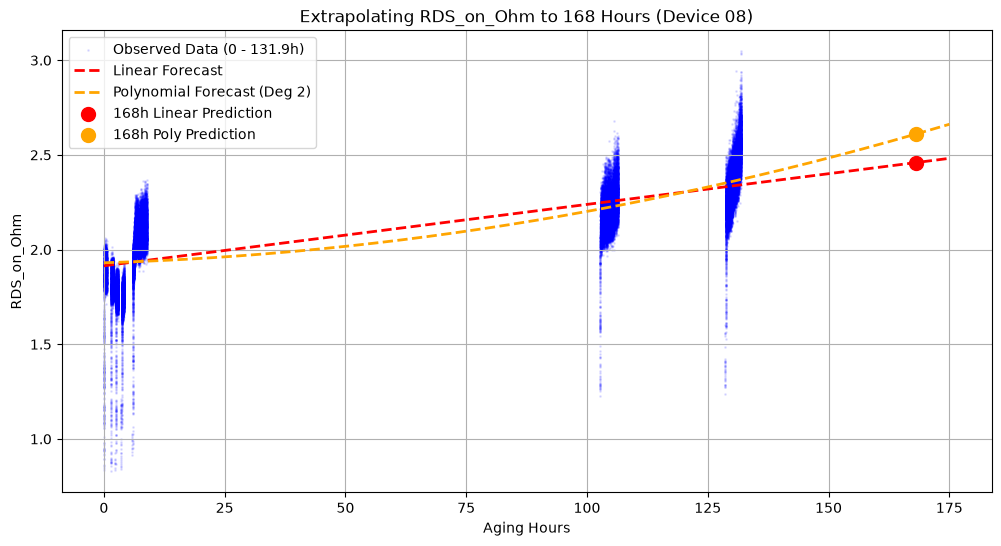

In [6]:
# 5. Visualization of the Extrapolation
plt.figure(figsize=(12, 6))
plt.scatter(X_train, y_train, color='blue', s=1, alpha=0.1, label='Observed Data (0 - 131.9h)')
X_plot = pd.DataFrame({'Aging_Hours': np.linspace(0, 175, 500)})
plt.plot(X_plot, model_linear.predict(X_plot), color='red', linestyle='--', linewidth=2, label='Linear Forecast')
plt.plot(X_plot, model_poly.predict(X_plot), color='orange', linestyle='--', linewidth=2, label='Polynomial Forecast (Deg 2)')
plt.scatter([168.0], [pred_168h_linear], color='red', s=100, zorder=5, label='168h Linear Prediction')
plt.scatter([168.0], [pred_168h_poly], color='orange', s=100, zorder=5, label='168h Poly Prediction')
plt.title('Extrapolating RDS_on_Ohm to 168 Hours (Device 08)')
plt.xlabel('Aging Hours')
plt.ylabel('RDS_on_Ohm')
plt.legend()
plt.grid(True)
plt.show()
